# Fig. 4 and Extended Data Fig. 8: breast cancer

Fig. 4 is a showcase of EnrichMap (null): a G0 weights, b maps, c cross-Moran, d hallmark correlations, e MDK and CTTN,
f-g HRD maps, h agreement with the ground truth. Extended Data Fig. 8: a H6 gene contributions, b EnrichMap (null; signed
inferred, inferred, up genes with true weights) against AUCell, GSVA, ssGSEA, Z score, Scanpy and GSDensity, c comparator
maps, d comparators against the ground truth. Source data are saved as CSV next to each figure.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import kruskal, linregress, mannwhitneyu, pearsonr, rankdata, spearmanr
from enrichmap.plotting._signature_correlation_heatmap import compute_corr_and_pval, get_star_annot

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)

# processed data directory
processed_data = project_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)


# scores saved by REV_Fig4_SupFig10_1_scores and REV_Fig4_SupFig10_1b_calibration; GSDensity relevance
scores_dir = working_dir + "data/rev_cache/Fig4_SupFig10/"
gsd_dir = working_dir + "data/gsd_cache/breast/"

In [5]:
from helpers import (
    steiger_z_fig4,
    bootstrap_spearman_fig4,
    _morans_i_continuous_fig4,
    gearys_c_continuous,
    spatial_knn_connectivity,
    zscore_per_slide,
    smooth_per_slide,
    knn_spatial_lag_matrix,
    cross_moran_statistics,
    pearson_with_columns_fig4,
    dutilleul_distance_classes,
    dutilleul_modified_ttest,
    partial_spearman,
    correlation_cluster_order,
    select_extreme_genes,
    contribution_cluster_order,
    scale_contribution_rows,
    contribution_morans_i,
    spot_coherence,
    colour_shades,
    set_box_ratio,
)

In [6]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
    "AUCell": "#86bf6e",
    "GSVA": "#c76663",
    "ssGSEA": "#8f6eb0",
    "Z score": "#866342",
    "Scanpy": "#cf83bd",
    "GSDensity": "#e3a33b",
}
spot_size = 2.1

In [7]:
# 1. Load data (09_00 / 09_01 cells 5-6), signatures (09_00 cells 7 and 14) and the EnrichMap scores
# X of this object is already log-normalised (saved by REV_Fig4_SupFig10_1_scores)
adata = sc.read_h5ad(processed_data + "adata_slides_0_3_scores.h5ad")
adata.obs["batch"] = adata.obs["batch"].astype(str)

upregulated_genes = [
    "CFLAR", "CALCOCO1", "YPEL3", "CST3", "SERINC1", "CLIP4", "PCYOX1", "TMEM59","RGS2", "YPEL5", "CD63", "KIAA1109",
    "CDH13", "GSN", "MR1", "CYB5R1", "AZGP1","ZFYVE1", "DMXL1", "EPS8L2", "PTTG1IP", "MIR22HG", "PSAP", "GOLGA8B",
    "NEAT1", "TXNIP", "MTRNR2L12"
]

downregulated_genes = [
    "NCAPD2", "PTBP1", "MPHOSPH9", "NUCKS1", "TCOF1", "SART3", "SNRPA", "KIF22", "HSP90AA1", "WBP11", "CAD", "SF3B2",
    "KHSRP", "WDR76", "NUP188", "HSP90AB1", "HNRNPM", "SMARCB1", "PNN", "RBBP7", "NPRL3", "USP10", "SGTA", "MRPL4",
    "PSMD3", "KPNB1", "CBX1", "LRRC59", "TMEM97", "NSD2", "PRPF19", "PTGES3", "CPSF6", "SRSF3", "TCERG1", "SMC4",
    "EIF4G1", "ZNF142", "MSH6", "MRPL37", "SFPQ", "STMN1", "ARID1A", "PROSER1", "DDX39A", "EXOSC9", "USP22", "DEK",
    "DUT", "ILF3", "DNMT1", "NASP", "HMGB1P5", "SRRM1", "GNL2", "RNF138", "SRSF1", "TRA2B", "SMPD4", "ANP32B", "HMGA1",
    "MDC1", "HADH", "ARHGDIA", "PRCC", "HDGF", "SF3B4", "UBAP2L", "ILF2", "PARP1", "LBR", "CNOT9", "PPRC1", "SSRP1",
    "CCT5", "DLAT", "HNRNPU", "LARP1", "SCAF4", "RRP1B", "RRP1", "CHCHD4", "GMPS", "RFC4", "SLBP", "PSIP1", "HNRNPK",
    "SKA3", "DIS3L", "USP39", "GPS1", "PA2G4", "HCFC1", "SLC19A1", "ETV4", "RAD23A", "DCTPP1", "RCC1", "EWSR1", "ALYREF",
    "PTMA", "HMGB1", "POM121", "MCMBP", "TEAD4", "CHAMP1", "TOP1", "PRRC2A", "RBM14", "HMGB1P6", "POM121C", "UHRF1"
]
proliferation = ["MKI67", "PCNA", "CCND1", "CCNE1", "CCNA1", "CCNB1", "MCM2", "MCM3", "MCM4", "MCM5", "MCM6", "MCM7", "H3F3A", "H3F3B"]

# read in the pickled gene sets
with open(project_dir + "hallmarks_genelists.pkl", "rb") as f:
    cancer_hallmark_genesets = pickle.load(f)

hallmark_names = {
    "H1": "Sustaining proliferative signalling", "H2": "Evading growth suppressors",
    "H3": "Avoiding immune destruction", "H4": "Enabling replicative immortality",
    "H5": "Tumour-promoting inflammation", "H6": "Activating invasion and metastasis",
    "H7": "Inducing angiogenesis", "H8": "Genome instability and mutation", "H9": "Resisting cell death",
    "H10": "Deregulating cellular energetics", "H11": "Senescent cells",
    "H12": "Nonmutational epigenetic reprogramming", "H13": "Unlocking phenotypic plasticity",
}
hallmarks = list(hallmark_names)

# EnrichMap (null) scores (signed programmes as up/down lists), null-model p-values, the
# fitted signed weights and the published gene_weights route of the signed programmes
with open(scores_dir + "scores.pkl", "rb") as f:
    saved = pickle.load(f)
scores = saved["scores"]
null_info = saved["null_info"]
published_route = saved["published_route"]
weights, weights_package = saved["weights"], saved["weights_package"]

# random gene sets of the procedure-matched nulls
with open(scores_dir + "null_scores.pkl", "rb") as f:
    nulls = pickle.load(f)


In [8]:
# 2. EnrichMap (null) scores per spot; GSDensity (Sup. Fig. 10 only): relevance x spots per slide (slide mean 1) of the
# HRD up genes, from the cache (GSDensity has no weights and no signed mode)
labels = {"null": "EnrichMap (null)"}
S = {label: scores[label].astype(np.float64) for label in labels.values()}

adata.obs["hrd_gsdensity"] = pd.read_csv(gsd_dir + "hrd_gt.csv", index_col=0).loc[
    adata.obs_names, "relevance_scaled"].values

slides = ["0", "3"]
patient = {"0": "Patient 1 (Luminal B)", "3": "Patient 2 (Her2+)"}
batch = adata.obs["batch"].values
coords = np.asarray(adata.obsm["spatial"], dtype=np.float64)
is_tumour = (adata.obs["tumour_cells"] == 1).values
tumour_masks = {b: is_tumour & (batch == b) for b in slides}
slide_masks = {b: batch == b for b in slides}

# score columns for the maps: {signature}_null_score
method_tag = {"EnrichMap (null)": "null"}
for meth, tag in method_tag.items():
    for s in S[meth].columns:
        adata.obs[f"{s}_{tag}_score"] = S[meth][s].values
methods = list(method_tag)
enrichmap_variants = methods[:2]
short = {"EnrichMap (null)": "null model"}

spots = pd.DataFrame({
    "spot_id": adata.obs_names,
    "patient": adata.obs["batch"].map(patient).values,
    "slide": batch,
    "x_pixel": coords[:, 0],
    "y_pixel": coords[:, 1],
})

In [9]:
# 3. Fig. 4a: signed G0 weights (the schematic is unchanged)
g0_w = weights["G0"]
panel_a = pd.DataFrame(
    [{"gene": g, "gene_set": gs, "in_dataset": g in adata.var_names,
      "signed_weight": g0_w.get(g, np.nan) if gs.startswith("G0") else np.nan}
     for gs, genes in [("G0 arrest, upregulated", upregulated_genes), ("G0 arrest, downregulated", downregulated_genes),
                       ("Proliferation", proliferation)] for g in genes]
)
# weights that em.tl.score fits from the up/down lists (the same rule)
panel_a["signed_weight_fitted_in_score"] = [
    weights_package["G0"].get(g, np.nan) if gs.startswith("G0") else np.nan
    for gs, g in zip(panel_a["gene_set"], panel_a["gene"])
]
scored = panel_a["signed_weight"].notna()
d_w = np.nanmax(np.abs(panel_a["signed_weight_fitted_in_score"] - panel_a["signed_weight"]))
same_sign = np.mean(np.sign(panel_a.loc[scored, "signed_weight_fitted_in_score"])
                    == np.sign(panel_a.loc[scored, "signed_weight"]))
n_flip = int(sum(g0_w[g] < 0 for g in upregulated_genes if g in g0_w))
n_flip_dn = int(sum(g0_w[g] > 0 for g in downregulated_genes if g in g0_w))
panel_a.to_csv(source_dir + "Fig4a_G0_weights.csv", index=False)

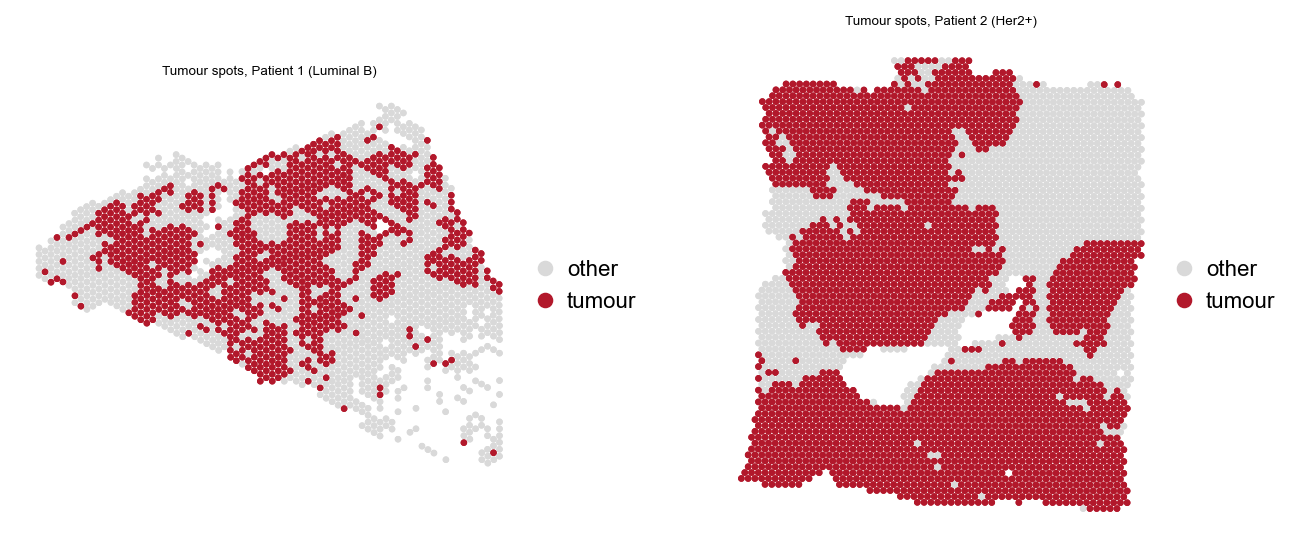

In [10]:
# 4. Fig. 4b: tumour spots, and the tumour-spot maps of G0 arrest and proliferation
adata.obs["tumour spots"] = pd.Categorical(np.where(is_tumour, "tumour", "other"), categories=["other", "tumour"])
adata.uns["tumour spots_colors"] = ["#d9d9d9", "#b2182b"]
sq.pl.spatial_scatter(
    adata,
    color="tumour spots",
    library_key="batch",
    library_id=slides,
    img_alpha=0.5,
    title=[f"Tumour spots, {patient[b]}" for b in slides],
    save="Fig4b_tumour_spots.pdf",
    shape=None,
    size=spot_size,
)
spots.assign(tumour_spot=is_tumour.astype(int)).to_csv(
    source_dir + "Fig4b_tumour_spots.csv", index=False)

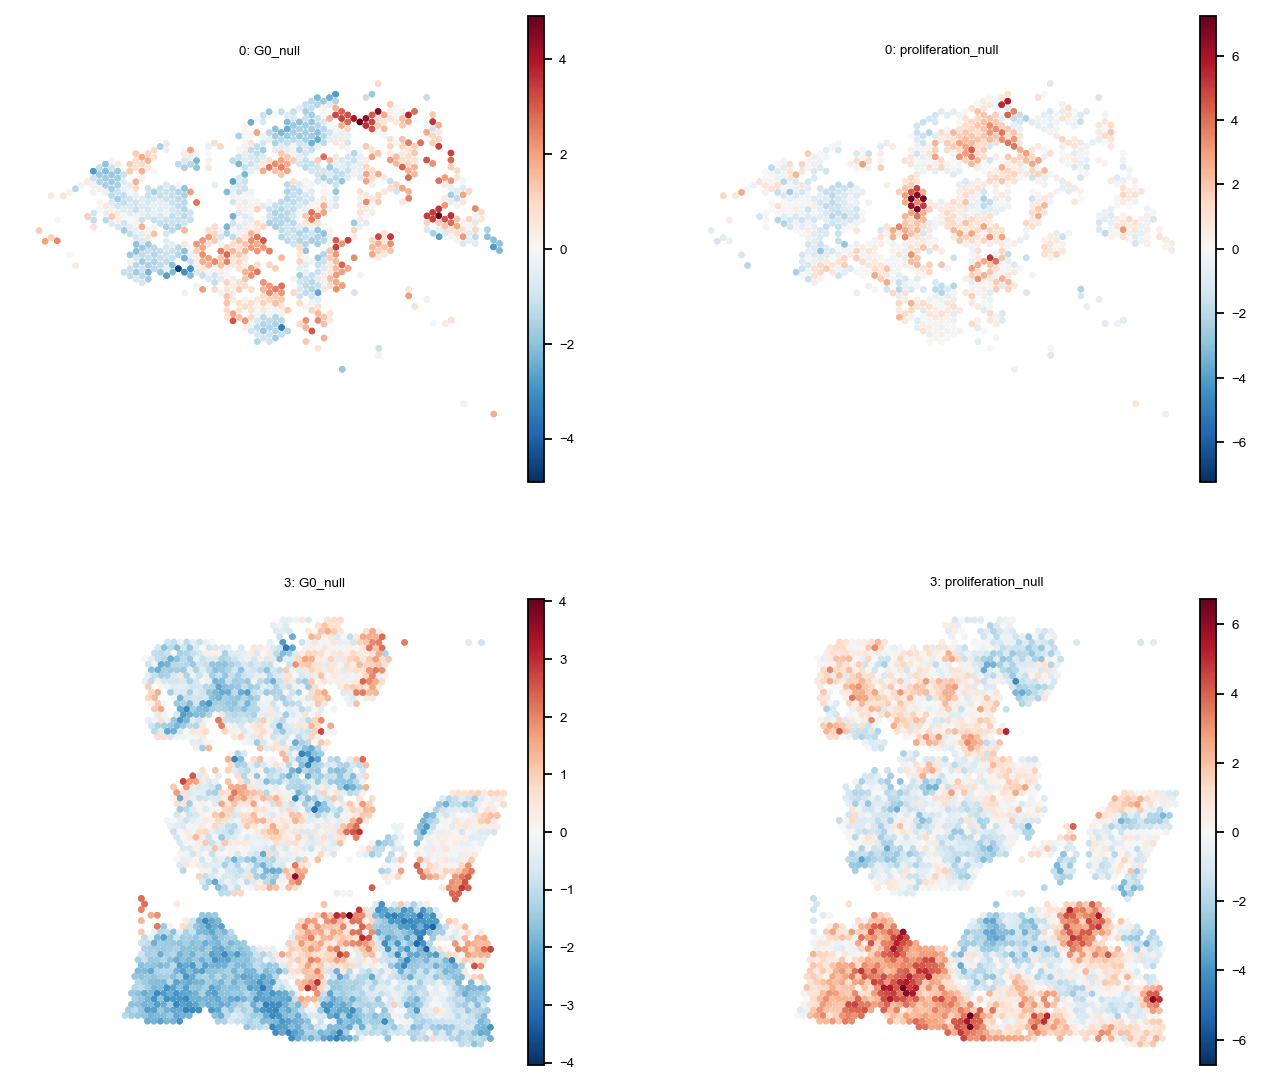

In [11]:
# rows: patient x signature
keys_4b = [f"{s}_{method_tag[meth]}_score" for s in ("G0", "proliferation") for meth in methods]
tumour = adata[is_tumour].copy()

em.pl.spatial_enrichmap(
    tumour,
    score_key=keys_4b,
    library_key="batch",
    ncols=2,
    save="Fig4b_maps.pdf",
    shape=None,
    size=2.1,
)
panel_b = spots.assign(tumour_spot=is_tumour.astype(int))
for key in keys_4b:
    panel_b[key] = np.where(is_tumour, adata.obs[key].values, np.nan)
panel_b.to_csv(source_dir + "Fig4b_maps.csv", index=False)

In [12]:
# 5. Fig. 4c: cross-Moran scatter (computation of em.pl.cross_moran_scatter) with parametric, Dutilleul and empirical
# p; null-P = G0 vs 200 random proliferation-like 14-gene sets, null-G0 = 200 random G0-like signed sets vs
# proliferation, every draw scored with EnrichMap (null)
lag = {b: knn_spatial_lag_matrix(coords[tumour_masks[b]]) for b in slides}
dutilleul = {b: dutilleul_distance_classes(coords[tumour_masks[b]]) for b in slides}
n_null = nulls["scores"]["nullP"]["EnrichMap (null)"].shape[1]

summary_rows, points = [], []
for meth in methods:
    for b in slides:
        m = tumour_masks[b]
        x = S[meth]["G0"].values[m]
        y = S[meth]["proliferation"].values[m]
        y_lag, quadrant, category, st = cross_moran_statistics(x, y, coords[m])
        d = dutilleul_modified_ttest(x, y_lag, dutilleul[b])
        nP = pearson_with_columns_fig4(x, lag[b] @ nulls["scores"]["nullP"][meth].values[m].astype(np.float64))
        nG = pearson_with_columns_fig4(y_lag, nulls["scores"]["nullG0"][meth].values[m].astype(np.float64))
        r = st["pearson_r"]
        summary_rows.append({
            "method": meth, "patient": patient[b], **st,
            "n_eff (Dutilleul)": d["n_eff"], "p Dutilleul": d["p"],
            "pearson_r without lag": pearsonr(x, y)[0],
            "null-P mean": nP.mean(), "null-P sd": nP.std(), "z vs null-P": (r - nP.mean()) / nP.std(),
            "p empirical null-P (one-sided)": (1 + (nP <= r).sum()) / (n_null + 1),
            "null-G0 mean": nG.mean(), "null-G0 sd": nG.std(), "z vs null-G0": (r - nG.mean()) / nG.std(),
            "p empirical null-G0 (one-sided)": (1 + (nG <= r).sum()) / (n_null + 1),
            "_nullP": nP, "_nullG0": nG,
        })
        points.append(pd.DataFrame({
            "method": meth, "spot_id": adata.obs_names[m], "patient": patient[b], "x_pixel": coords[m, 0],
            "y_pixel": coords[m, 1], "G0_score": x, "spatial_lag_proliferation_score": y_lag,
            "quadrant": quadrant, "category": category,
        }))
crossmoran = pd.DataFrame(summary_rows)
panel_c = pd.concat(points, ignore_index=True)
print(crossmoran.drop(columns=["_nullP", "_nullG0"]).set_index(["method", "patient"])[[
    "pearson_r", "p_value", "n_eff (Dutilleul)", "p Dutilleul", "z vs null-P", "p empirical null-P (one-sided)",
    "z vs null-G0", "p empirical null-G0 (one-sided)", "n_anti_correlated", "n_discordant",
]].to_string(float_format=lambda v: f"{v:.3g}"))

                                        pearson_r   p_value  n_eff (Dutilleul)  p Dutilleul  z vs null-P  p empirical null-P (one-sided)  z vs null-G0  p empirical null-G0 (one-sided)  n_anti_correlated  n_discordant
method           patient                                                                                                                                                                                                
EnrichMap (null) Patient 1 (Luminal B)     -0.131  5.02e-05                149        0.111       -0.827                           0.234         -1.11                            0.149                490           463
                 Patient 2 (Her2+)         -0.646 7.48e-305               53.5     1.55e-07        -3.17                         0.00498         -2.06                          0.00995               1917           668


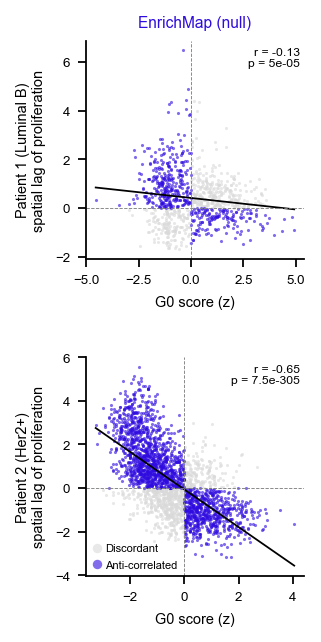

In [13]:
# Fig. 4c figure
fig, axes = plt.subplots(2, 1, figsize=(2.3, 4.4), squeeze=False, gridspec_kw={"hspace": 0.45})
for j, meth in enumerate(methods):
    for i, b in enumerate(slides):
        ax = axes[i, j]
        d_ = panel_c[(panel_c.method == meth) & (panel_c.patient == patient[b])]
        st = crossmoran[(crossmoran.method == meth) & (crossmoran.patient == patient[b])].iloc[0]
        anti = d_["category"].values == "Anti-correlated"
        ax.scatter(d_["G0_score"][~anti], d_["spatial_lag_proliferation_score"][~anti], s=2, alpha=0.6,
                   color="#d9d9d9", linewidths=0, label="Discordant")
        ax.scatter(d_["G0_score"][anti], d_["spatial_lag_proliferation_score"][anti], s=2, alpha=0.6,
                   color=colours[meth], linewidths=0, label="Anti-correlated")
        xx = np.linspace(d_["G0_score"].min(), d_["G0_score"].max(), 10)
        ax.plot(xx, st.ols_intercept + st.ols_slope * xx, color="k", lw=0.8)
        ax.axhline(0, color="grey", lw=0.4, ls="--")
        ax.axvline(0, color="grey", lw=0.4, ls="--")
        ax.text(0.98, 0.97, f"r = {st.pearson_r:.2f}\np = {st.p_value:.2g}",
                transform=ax.transAxes, ha="right", va="top", fontsize=5.5,
                bbox={"facecolor": "white", "alpha": 0.8, "lw": 0, "pad": 1})
        ax.set_xlabel("G0 score (z)", fontsize=6.5)
        if j == 0:
            ax.set_ylabel(f"{patient[b]}\nspatial lag of proliferation", fontsize=6.5)
        if i == 0:
            ax.set_title(meth, fontsize=7, color=colours[meth])
        ax.tick_params(labelsize=6)
        ax.grid(False)
        sns.despine(ax=ax)
        if i == 1:
            ax.legend(fontsize=5, frameon=False, loc="lower left", markerscale=3, handletextpad=0.2)
set_box_ratio(fig, ratio=1)
plt.savefig(figure_dir + "Fig4c_crossmoran.pdf", bbox_inches="tight")
plt.show()
panel_c.to_csv(source_dir + "Fig4c_crossmoran.csv", index=False)

In [14]:
# 6. Fig. 4d: Spearman correlations of G0 arrest, proliferation and the 13 hallmarks on tumour spots (computation of
# em.pl.signature_correlation_heatmap)
score_keys = ["G0", "proliferation"] + hallmarks
signature_names = {"G0": "G0 arrest", "proliferation": "Proliferation", **hallmark_names}
tick = {"G0": "G0", "proliferation": "Prolif", **{h: h for h in hallmarks}}

corr, pvals, stars, order, heat_rows = {}, {}, {}, {}, []
for meth in methods:
    for b in slides:
        sub = S[meth].loc[tumour_masks[b], score_keys].dropna()
        c_, p_ = compute_corr_and_pval(sub)
        corr[(meth, b)], pvals[(meth, b)], stars[(meth, b)] = c_, p_, get_star_annot(p_)
        order[(meth, b)] = [score_keys[i] for i in correlation_cluster_order(c_)]
        for ri, rk in enumerate(order[(meth, b)]):
            for ci, ck in enumerate(order[(meth, b)]):
                heat_rows.append({
                    "method": meth, "patient": patient[b], "n_spots": len(sub),
                    "row_position": ri + 1, "row_signature": rk, "row_label": signature_names[rk],
                    "column_position": ci + 1, "column_signature": ck, "column_label": signature_names[ck],
                    "spearman_rho": c_.loc[rk, ck], "p_value": p_.loc[rk, ck],
                    "significance": stars[(meth, b)].loc[rk, ck],
                })
panel_d = pd.DataFrame(heat_rows)

In [15]:
# Fig. 4d claims: rho, rank, Dutilleul p, random-set null (null-H) and composition-adjusted partial rho
claims_list = [("G0", "H3"), ("G0", "H5"), ("G0", "H6"), ("proliferation", "H1"), ("proliferation", "H9"), ("proliferation", "H4")]

# cell2location q05 abundances: compartment fractions
q05 = adata.obsm["q05_cell_abundance_w_sf"].copy()
q05.columns = [str(c).replace("q05cell_abundance_w_sf_", "") for c in q05.columns]
q05 = q05.drop(columns=[c for c in q05.columns if c == "cnv_labels"]).astype(float)
compartments = {
    "cancer": [c for c in q05.columns if c.startswith("Cancer")],
    "normal epithelial": ["Luminal Progenitors", "Mature Luminal", "Myoepithelial"],
    "immune": ["B cells Memory", "B cells Naive", "Cycling T-cells", "Cycling_Myeloid", "DCs", "Macrophage", "Monocyte",
               "NK cells", "NKT cells", "Plasmablasts", "T cells CD4+", "T cells CD8+"],
    "stromal": ["CAFs MSC iCAF-like", "CAFs myCAF-like", "Cycling PVL", "Endothelial ACKR1", "Endothelial CXCL12",
                "Endothelial Lymphatic LYVE1", "Endothelial RGS5", "PVL Differentiated", "PVL Immature"],
}
FR = pd.DataFrame({k: q05[c].sum(1) / q05.sum(1) for k, c in compartments.items()})
FR["Cancer Cycling"] = q05["Cancer Cycling"] / q05.sum(1)

# fractions processed like the scores: per-slide z-score and 6-NN smoothing
fr_z = pd.DataFrame(zscore_per_slide(FR.values, batch), index=adata.obs_names, columns=FR.columns)
fr_smooth = pd.DataFrame(smooth_per_slide(fr_z.values, batch, coords), index=adata.obs_names, columns=FR.columns)
FR_proc = {meth: fr_smooth for meth in methods}

# null-H: 30 random expression-matched sets of each hallmark's size, scored with EnrichMap (null)
n_null_h = 30
summary_rows, comp_rows = [], []
for meth in methods:
    NH = nulls["scores"]["nullH"][meth]
    for b in slides:
        m = tumour_masks[b]
        Zc = FR_proc[meth].loc[m, ["immune", "stromal"]].values
        for s in ("G0", "proliferation"):
            xs = S[meth][s].values[m]
            rs = rankdata(xs)
            rhos = {h: corr[(meth, b)].loc[s, h] for h in hallmarks}
            ranked = sorted(hallmarks, key=lambda h: -rhos[h])
            for h in hallmarks:
                cols = [f"nullH_{h}_{k:02d}" for k in range(n_null_h)]
                nv = pearson_with_columns_fig4(rs, rankdata(NH[cols].values[m].astype(np.float64), axis=0))
                d = dutilleul_modified_ttest(rs, rankdata(S[meth][h].values[m]), dutilleul[b])
                summary_rows.append({
                    "method": meth, "patient": patient[b], "score": s, "hallmark": h, "name": hallmark_names[h],
                    "claimed in text": (s, h) in claims_list, "rho": rhos[h],
                    "rank (1 = most positive)": ranked.index(h) + 1, "p Dutilleul": d["p"], "n_eff": d["n_eff"],
                    "partial rho | immune, stromal": partial_spearman(xs, S[meth][h].values[m], Zc),
                    "null mean": nv.mean(), "null sd": nv.std(), "z vs null-H": (rhos[h] - nv.mean()) / nv.std(),
                    "null q2.5": np.quantile(nv, 0.025), "null q97.5": np.quantile(nv, 0.975),
                })
        rec = {"method": meth, "patient": patient[b]}
        for s in ("G0", "proliferation"):
            xs = S[meth][s].values[m]
            rec[f"rho({s}, Cancer Cycling fraction)"] = spearmanr(xs, FR["Cancer Cycling"][m])[0]
            for c in ("immune", "stromal", "cancer"):
                rec[f"rho({s}, {c} fraction; same operator)"] = spearmanr(xs, FR_proc[meth][c][m])[0]
        comp_rows.append(rec)
hallmark_rows = pd.DataFrame(summary_rows)
composition = pd.DataFrame(comp_rows)

claims = hallmark_rows[hallmark_rows["claimed in text"]].copy()
claims["claim"] = claims.score.str.replace("proliferation", "prolif") + " ~ " + claims.hallmark
claims["rho > 0 and Dutilleul p < 0.05"] = (claims.rho > 0) & (claims["p Dutilleul"] < 0.05)
claims["above null-H 97.5%"] = claims.rho > claims["null q97.5"]
show = claims.pivot_table(index=["claim", "patient"], columns="method",
                          values=["rho", "partial rho | immune, stromal", "z vs null-H"])
print(show.reindex(columns=methods, level=1).round(3).to_string())
print("\nclaim holds in both patients (rho > 0, Dutilleul p < 0.05 / above the null-H 97.5% quantile):")
claim_holds = pd.concat([
    claims.groupby(["claim", "method"])["rho > 0 and Dutilleul p < 0.05"].all().unstack().reindex(columns=methods),
    claims.groupby(["claim", "method"])["above null-H 97.5%"].all().unstack().reindex(columns=methods)
    .add_suffix(" | null-H"),
], axis=1)
print(claim_holds.to_string())
print(composition.set_index(["patient", "method"]).T.round(3).to_string())

                                  partial rho | immune, stromal              rho      z vs null-H
method                                         EnrichMap (null) EnrichMap (null) EnrichMap (null)
claim       patient                                                                              
G0 ~ H3     Patient 1 (Luminal B)                         0.393            0.721            2.253
            Patient 2 (Her2+)                             0.253            0.484            2.712
G0 ~ H5     Patient 1 (Luminal B)                         0.452            0.745            3.197
            Patient 2 (Her2+)                             0.334            0.515            1.985
G0 ~ H6     Patient 1 (Luminal B)                         0.437            0.666            1.813
            Patient 2 (Her2+)                             0.050            0.070           -1.208
prolif ~ H1 Patient 1 (Luminal B)                        -0.007           -0.012            2.101
            Patient 

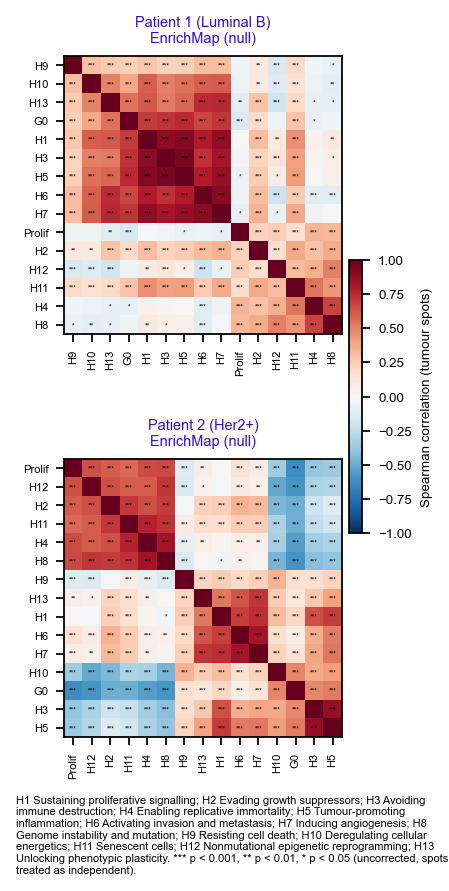

In [16]:
# Fig. 4d figure: clustered heatmaps per patient
fig, axes = plt.subplots(2, 1, figsize=(2.8, 5.6), squeeze=False, gridspec_kw={"hspace": 0.45})
for i, b in enumerate(slides):
    for j, meth in enumerate(methods):
        ax = axes[i, j]
        keys = order[(meth, b)]
        M = corr[(meth, b)].loc[keys, keys].values
        A = stars[(meth, b)].loc[keys, keys].values
        im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
        for r_ in range(len(keys)):
            for c_ in range(len(keys)):
                if A[r_, c_]:
                    ax.text(c_, r_, A[r_, c_], ha="center", va="center", fontsize=3, color="k")
        ax.set_xticks(range(len(keys)))
        ax.set_yticks(range(len(keys)))
        ax.set_xticklabels([tick[k] for k in keys], rotation=90, fontsize=5)
        ax.set_yticklabels([tick[k] for k in keys], fontsize=5)
        ax.set_title(f"{patient[b]}\n{meth}", fontsize=6.5, color=colours[meth])
        ax.grid(False)
cb = fig.colorbar(im, ax=axes, shrink=0.4, pad=0.02)
cb.set_label("Spearman correlation (tumour spots)", fontsize=6)
cb.ax.tick_params(labelsize=6)
fig.text(0.1, 0.0, "; ".join(f"{h} {n}" for h, n in hallmark_names.items())
         + ". *** p < 0.001, ** p < 0.01, * p < 0.05 (uncorrected, spots treated as independent).",
         fontsize=5, wrap=True)
set_box_ratio(fig)
plt.savefig(figure_dir + "Fig4d_hallmark_heatmaps.pdf", bbox_inches="tight")
plt.show()
panel_d.to_csv(source_dir + "Fig4d_hallmark_heatmaps.csv", index=False)

              patient           method  rho(MDK, G0)  rho(MDK, H6)  rho(CTTN, G0)  rho(CTTN, H6)
Patient 1 (Luminal B) EnrichMap (null)        -0.613        -0.606         -0.215         -0.237
    Patient 2 (Her2+) EnrichMap (null)        -0.169         0.227         -0.379         -0.072


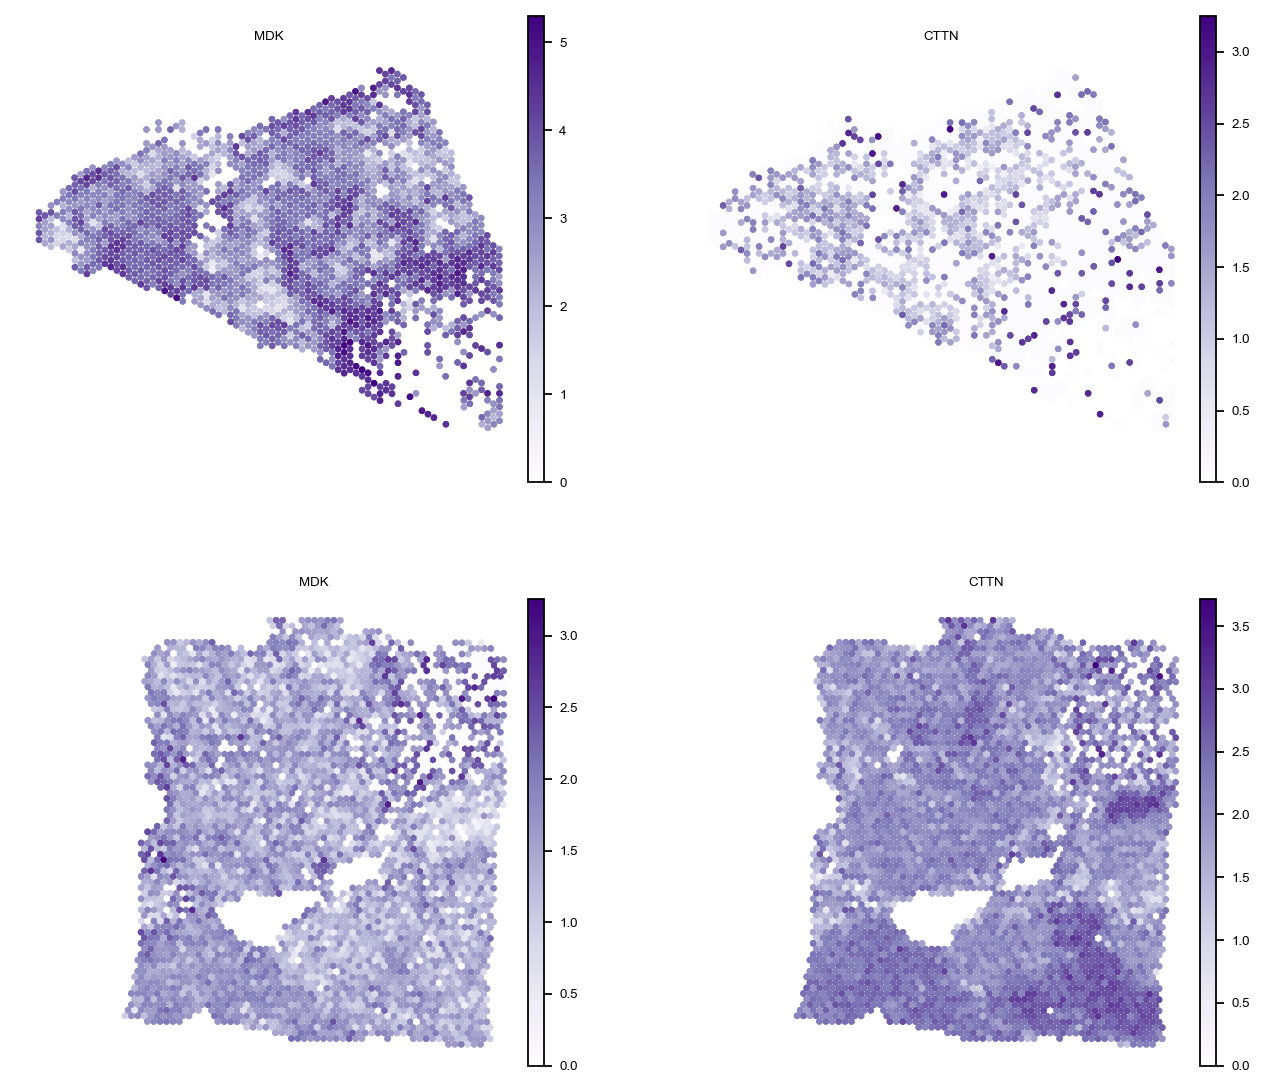

In [17]:
# 7. Fig. 4e: MDK and CTTN expression (log1p of counts per 10,000), all spots of each slide
sq.pl.spatial_scatter(
    adata,
    color=["MDK", "CTTN"],
    library_key="batch",
    ncols=2,
    save=f"Fig4e_expression_maps.pdf",
    shape=None,
    size=spot_size,
    cmap="Purples"
)
expr = sc.get.obs_df(adata, keys=["MDK", "CTTN"])
spots.assign(MDK_log1p_norm=expr["MDK"].values, CTTN_log1p_norm=expr["CTTN"].values).to_csv(
    source_dir + "Fig4e_expression_maps.csv", index=False)

# text claim (Fig. 4e): MDK / CTTN in G0-associated invasive (H6) regions (tumour spots)
summary_rows = []
for b in slides:
    m = tumour_masks[b]
    for meth in methods:
        rec = {"patient": patient[b], "method": meth}
        for g in ("MDK", "CTTN"):
            for s in ("G0", "H6"):
                rec[f"rho({g}, {s})"] = spearmanr(expr[g].values[m], S[meth][s].values[m])[0]
        summary_rows.append(rec)
expr_assoc = pd.DataFrame(summary_rows)
print(expr_assoc.round(3).to_string(index=False))

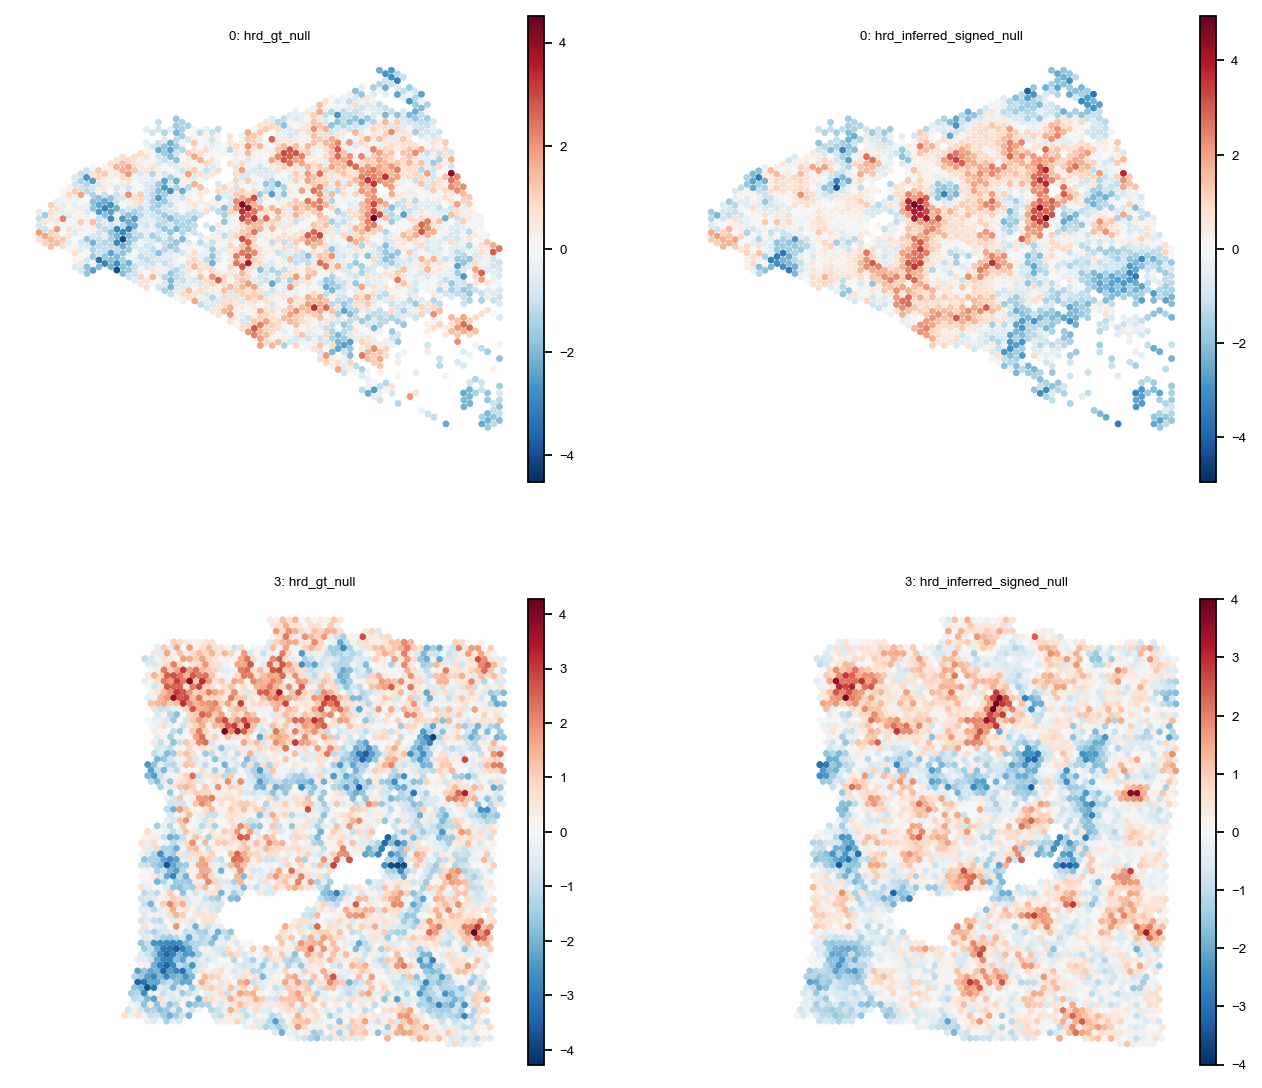

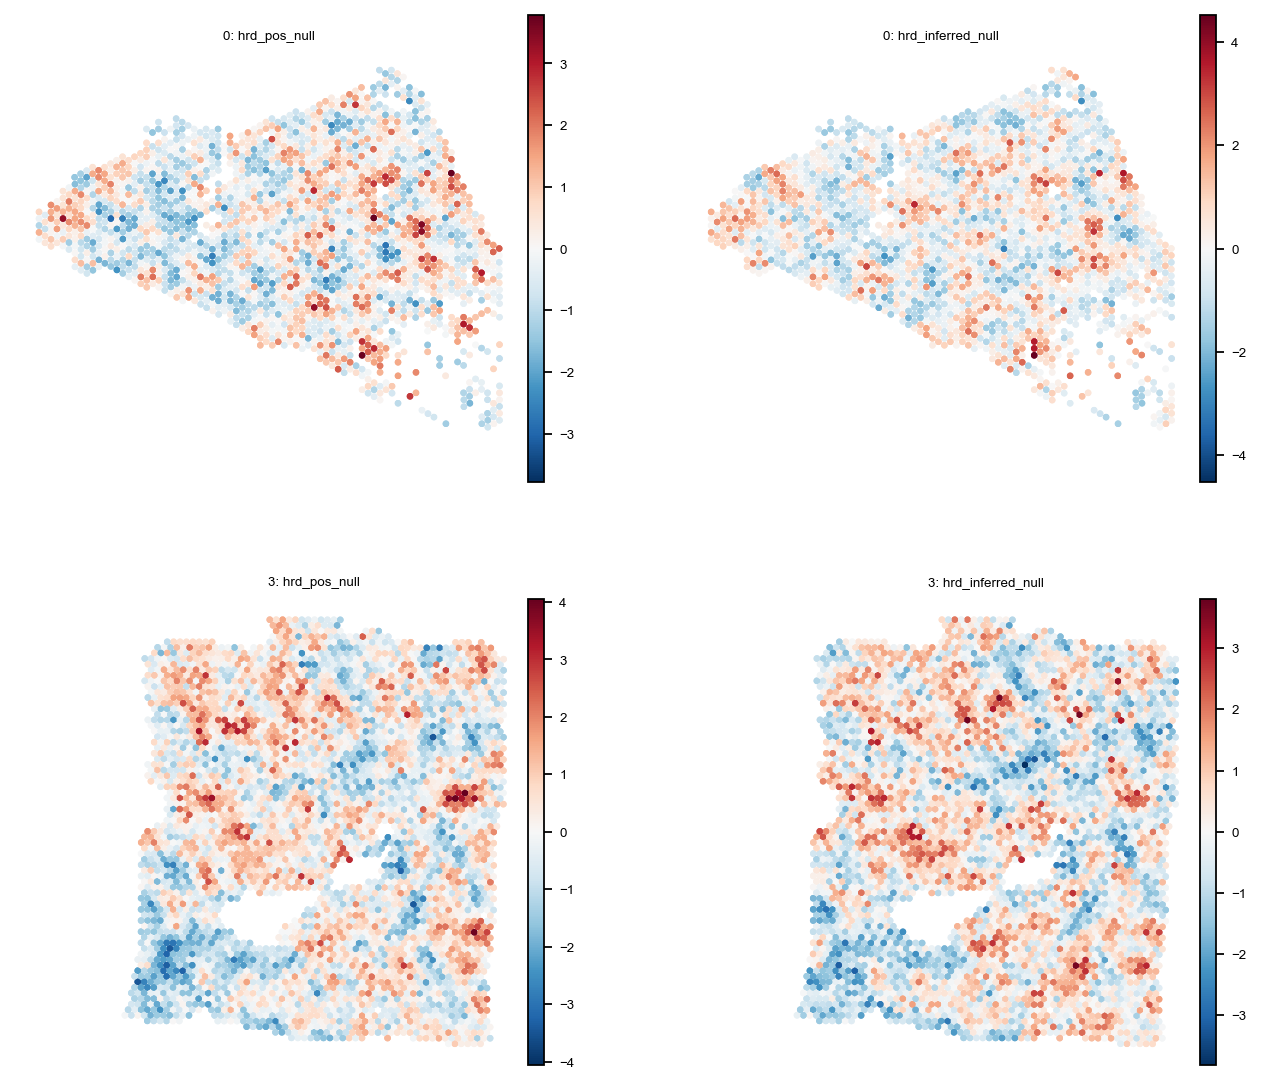

In [18]:
# 8. Fig. 4f-g: HRD maps, all spots; rows = patient x condition
keys_4f = ["hrd_gt_null_score", "hrd_inferred_signed_null_score"]
keys_4g = ["hrd_pos_null_score", "hrd_inferred_null_score"]

for keys, stem in ((keys_4f, "4f_hrd_maps"), (keys_4g, "4g_hrd_up_maps")):
    em.pl.spatial_enrichmap(
        adata,
        score_key=keys,
        library_key="batch",
        ncols=2,
        vcenter=0,
        save=f"Fig{stem}.pdf",
        shape=None,
        size=spot_size,
    )
    maps = spots.copy()
    for key in dict.fromkeys(keys):
        maps[key] = adata.obs[key].values
    maps.to_csv(source_dir + f"Fig{stem}.csv", index=False)

In [19]:
# 9. Fig. 4h: per-spot agreement with the ground truth and Steiger Z (09_01 cells 20, 22); the ground truth (Jacobson
# weights) is an EnrichMap (null) score
conditions = [
    ("hrd_inferred_signed", "Signed inferred"),
    ("hrd_inferred", "Inferred weights"),
    ("hrd_pos", "Up genes, true positive weights (published label 'Unweighted (raw)')"),
]
cond_short = {"hrd_inferred_signed": "Signed inferred", "hrd_inferred": "Inferred weights", "hrd_pos": "Up, true weights",}
pairs = [("Raw vs inferred", "hrd_pos", "hrd_inferred"),
         ("Raw vs signed inferred", "hrd_pos", "hrd_inferred_signed"),
         ("Inferred vs signed inferred", "hrd_inferred", "hrd_inferred_signed")]

# ground truth and HRD scores
hrd_frames = {}
for v in enrichmap_variants:
    o = S[v][["hrd_gt", "hrd_inferred_signed", "hrd_inferred", "hrd_pos"]].copy()
    hrd_frames[v] = o

stat_rows, steiger_rows = [], []
for v in enrichmap_variants:
    for scope, m in [("both patients pooled", np.ones(adata.n_obs, bool))] + [(patient[b], slide_masks[b]) for b in slides]:
        o = hrd_frames[v].loc[m]
        x = o["hrd_gt"].values
        for col, label in conditions:
            y = o[col].values
            fit = linregress(x, y)
            rho, p_rho = spearmanr(x, y)
            stat_rows.append({"ground-truth variant": v, "spots": scope, "condition": label, "score_column": col,
                              "method": v, "n_spots": len(x),
                              "pearson_r": np.corrcoef(x, y)[0, 1], "spearman_rho": rho, "spearman_p": p_rho,
                              "ols_slope": fit.slope, "ols_intercept": fit.intercept})
        for label, a, c in pairs:
            r12, r13 = np.corrcoef(x, o[a])[0, 1], np.corrcoef(x, o[c])[0, 1]
            r23 = np.corrcoef(o[a], o[c])[0, 1]
            Z, p = steiger_z_fig4(r12, r13, r23, n=len(x))
            steiger_rows.append({"ground-truth variant": v, "spots": scope, "comparison": label,
                                 "r12 (first vs GT)": r12, "r13 (second vs GT)": r13, "r23 (first vs second)": r23,
                                 "n_spots": len(x), "steiger_z_fig4": Z, "p_two_sided": p})
hrd_stats = pd.DataFrame(stat_rows)
hrd_steiger = pd.DataFrame(steiger_rows)
print(hrd_stats.pivot_table(index=["spots", "condition"], columns="ground-truth variant", values="spearman_rho")
      .reindex(columns=enrichmap_variants).round(3).to_string())
print(hrd_steiger.pivot_table(index=["spots", "comparison"], columns="ground-truth variant", values="steiger_z_fig4")
      .reindex(columns=enrichmap_variants).round(2).to_string())

ground-truth variant                                                                        EnrichMap (null)
spots                 condition                                                                             
Patient 1 (Luminal B) Inferred weights                                                                 0.535
                      Signed inferred                                                                  0.696
                      Up genes, true positive weights (published label 'Unweighted (raw)')             0.693
Patient 2 (Her2+)     Inferred weights                                                                 0.661
                      Signed inferred                                                                  0.823
                      Up genes, true positive weights (published label 'Unweighted (raw)')             0.796
both patients pooled  Inferred weights                                                                 0.616
                   

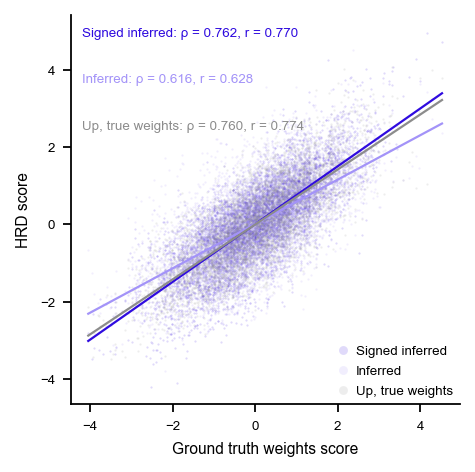

In [20]:
# Fig. 4h: Three methods overlaid in one panel
fig, ax = plt.subplots(1, 1, figsize=(3.2, 3.2))

methods = [
    ("hrd_inferred_signed", "Signed inferred", "#2f0bdf"),
    ("hrd_inferred", "Inferred", "#a393f8"),
    ("hrd_pos", "Up, true weights", "#8c8c8c"),
]

v = enrichmap_variants[0]
O = hrd_frames[v]
x = O["hrd_gt"].values

for i, (col, label, color) in enumerate(methods):
    st = hrd_stats[
        (hrd_stats["ground-truth variant"] == v)
        & (hrd_stats.spots == "both patients pooled")
        & (hrd_stats.score_column == col)
    ].iloc[0]

    # Scatter
    ax.scatter(
        x,
        O[col].values,
        s=1,
        alpha=0.15,
        color=color,
        linewidths=0,
        rasterized=False,
        label=label,
    )

    # Regression line
    xx = np.linspace(x.min(), x.max(), 100)
    ax.plot(xx, st.ols_intercept + st.ols_slope * xx, color=color, lw=1)

    # Correlations
    ax.text(
        0.03,
        0.97 - i * 0.12,
        f"{label}: ρ = {st.spearman_rho:.3f}, r = {st.pearson_r:.3f}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=6,
        color=color,
    )

ax.set_xlabel("Ground truth weights score", fontsize=7)
ax.set_ylabel("HRD score", fontsize=7)

ax.tick_params(labelsize=6)
ax.legend(frameon=False, fontsize=6, markerscale=4, loc="lower right")
ax.grid(False)
sns.despine(ax=ax)

set_box_ratio(fig, ratio=1, axes=[ax])

plt.savefig(
    figure_dir + "Fig4h_hrd_vs_ground_truth.pdf",
    bbox_inches="tight",
    dpi=600,
)
plt.show()

# Source data
panel_h = spots.copy()

for col, label, color in methods:
    panel_h[f"{col}_{method_tag[v]}_score"] = O[col].values

panel_h[f"hrd_gt_{method_tag[v]}_score"] = x

panel_h.to_csv(source_dir + "Fig4h_hrd_vs_ground_truth.csv", index=False)
hrd_steiger[hrd_steiger.spots == "both patients pooled"].to_csv(
    source_dir + "Fig4h_steiger_z.csv", index=False)

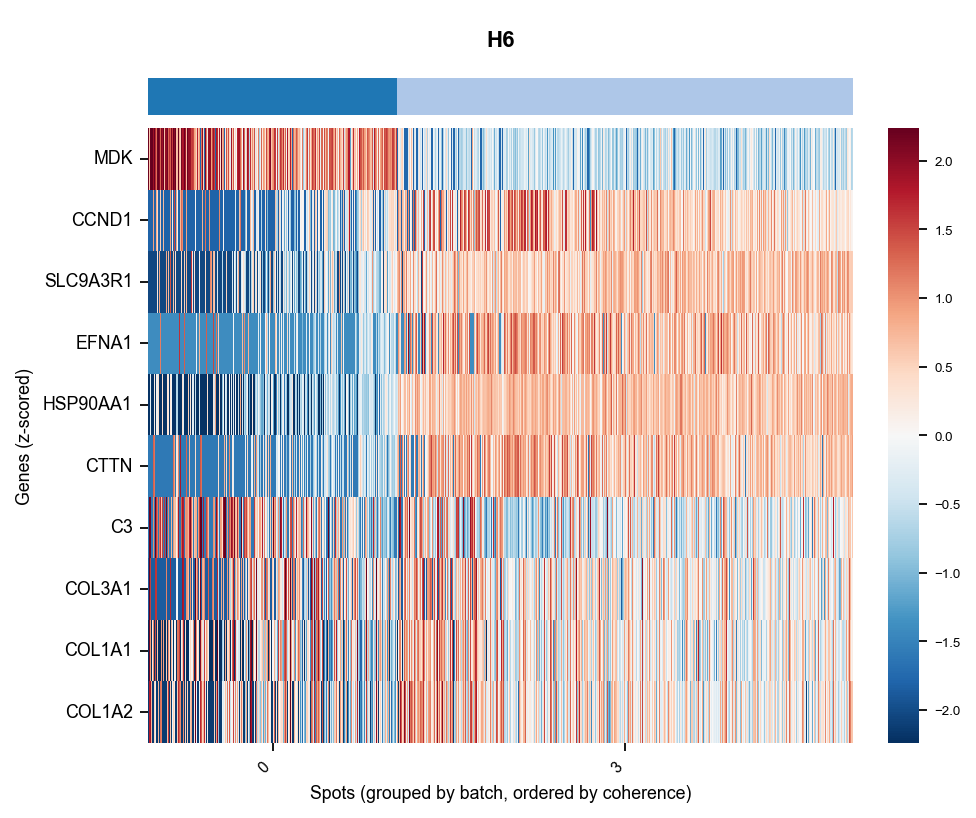

In [21]:
# H6 gene contributions (09_00 cell 22): the genes discussed in the manuscript, the top 10 of the previous submission.
# With within-slide CV weights they are no longer the 10 largest contributors, so they are listed here, not selected
h6_genes = ["MDK", "CCND1", "SLC9A3R1", "EFNA1", "HSP90AA1", "CTTN", "C3", "COL3A1", "COL1A1", "COL1A2"]
adata.uns["gene_contributions"]["H6"] = {g: adata.uns["gene_contributions"]["H6_null"][g] for g in h6_genes}
em.pl.gene_contributions_heatmap(
    adata,
    score_key="H6",
    groupby="batch",
    top_n_genes=10,
    bottom_n_genes=0,
    figsize=(6, 5),
    save="ExtendedDataFig8a_gene_contributions.pdf",
)
h6_contrib = pd.DataFrame(adata.uns["gene_contributions"]["H6"], index=spots.index)
spots.join((h6_contrib - h6_contrib.mean()) / h6_contrib.std(ddof=0)).to_csv(
    source_dir + "ExtendedDataFig8a_gene_contributions.csv", index=False)

In [22]:
# 11. Comparison with other methods on the 124 HRD up genes (09_01 cell 26)
from score_signatures import score_signatures

benchmark_sigs = {"hrd": list(weights["hrd_pos"].keys())}

adata = score_signatures(
    adata,
    signatures_dict=benchmark_sigs,
    methods=["aucell", "scanpy", "ssgsea", "gsva", "zscore"],
)

comparators = {"AUCell": "hrd_aucell", "GSVA": "hrd_gsva", "ssGSEA": "hrd_ssgsea", "Z score": "hrd_zscore", "Scanpy": "hrd_scanpy", "GSDensity": "hrd_gsdensity"}
comp = pd.DataFrame({lab: adata.obs[col].values.astype(np.float64) for lab, col in comparators.items()}, index=adata.obs_names)

In [23]:
# 12. Sup. Fig. 10b: bootstrapped Spearman rho with the ground truth (09_01 cells 24, 28): EnrichMap (null) with signed
# inferred, inferred and true up-gene weights, the comparators and GSDensity; every pair is resampled with the same seed, so the 1,000 replicates are paired across conditions
em_conditions = [("hrd_pos", "Upregulated in HRD (positive weights)"), ("hrd_inferred", "Inferred"), ("hrd_inferred_signed", "Signed inferred")]
n_boot = 1000

series = {}
for v in enrichmap_variants:
    for col, label in em_conditions:
        series[f"{v}|{label}"] = S[v][col].values
for meth in comp.columns:
    series[f"{meth}|up genes"] = comp[meth].values

boot, full = {}, {}
for v in enrichmap_variants:
    gt = S[v]["hrd_gt"].values
    for k, y in series.items():
        boot[(v, k)] = bootstrap_spearman_fig4(gt, y, n_boot=n_boot)
        full[(v, k)] = spearmanr(gt, y)[0]

boot_records, boot_rows, test_rows = [], [], []
for v in enrichmap_variants:
    named = [(label, f"{v}|{label}", v) for _, label in em_conditions] + [
        (m_, f"{m_}|up genes", m_) for m_ in comp.columns]
    boots = {}
    for label, k, meth in named:
        boots[label] = boot[(v, k)]
        q1, med, q3 = np.percentile(boots[label], [25, 50, 75])
        boot_records.append(pd.DataFrame({"ground-truth variant": v, "condition": label, "method": meth,
                                          "bootstrap_replicate": np.arange(1, n_boot + 1),
                                          "spearman_rho": boots[label]}))
        boot_rows.append({"ground-truth variant": v, "condition": label, "method": meth,
                          "rho_full_data": full[(v, k)], "bootstrap_median": med, "bootstrap_q1": q1,
                          "bootstrap_q3": q3, "bootstrap_2.5%": np.percentile(boots[label], 2.5),
                          "bootstrap_97.5%": np.percentile(boots[label], 97.5),
                          "bootstrap_min": boots[label].min(), "bootstrap_max": boots[label].max()})
    cond_labels = [label for _, label in em_conditions]
    for a, c in [(cond_labels[0], cond_labels[1]), (cond_labels[1], cond_labels[2]), (cond_labels[0], cond_labels[2]),
                 ("GSDensity", cond_labels[2]), ("GSDensity", cond_labels[1])]:
        U, p = mannwhitneyu(boots[a], boots[c], alternative="two-sided")
        diff = boots[c] - boots[a]
        test_rows.append({"ground-truth variant": v, "comparison": f"{c} - {a}",
                          "Mann-Whitney U (09_01 cell 24)": U, "Mann-Whitney p": p,
                          "paired bootstrap median difference": np.median(diff),
                          "paired bootstrap 2.5%": np.quantile(diff, 0.025),
                          "paired bootstrap 97.5%": np.quantile(diff, 0.975),
                          "fraction of replicates > 0": np.mean(diff > 0)})
    H, p = kruskal(*[boots[k] for k in cond_labels])
    test_rows.append({"ground-truth variant": v, "comparison": " vs ".join(cond_labels), "Kruskal-Wallis H": H,
                      "Kruskal-Wallis p": p})
panel_s10b = pd.concat(boot_records, ignore_index=True)
s10b_summary = pd.DataFrame(boot_rows)
s10b_tests = pd.DataFrame(test_rows)
print(s10b_summary.pivot_table(index="condition", columns="ground-truth variant", values="bootstrap_median")
      .reindex(columns=enrichmap_variants).round(3).to_string())
print(s10b_tests.dropna(subset=["paired bootstrap median difference"])[[
    "ground-truth variant", "comparison", "paired bootstrap median difference", "paired bootstrap 2.5%",
    "paired bootstrap 97.5%"]].round(4).to_string(index=False))

ground-truth variant                   EnrichMap (null)
condition                                              
AUCell                                            0.046
GSDensity                                         0.094
GSVA                                              0.101
Inferred                                          0.616
Scanpy                                            0.089
Signed inferred                                   0.762
Upregulated in HRD (positive weights)             0.760
Z score                                           0.073
ssGSEA                                            0.052
ground-truth variant                                              comparison  paired bootstrap median difference  paired bootstrap 2.5%  paired bootstrap 97.5%
    EnrichMap (null)        Inferred - Upregulated in HRD (positive weights)                             -0.1441                -0.1567                 -0.1327
    EnrichMap (null)                              Signed inferre

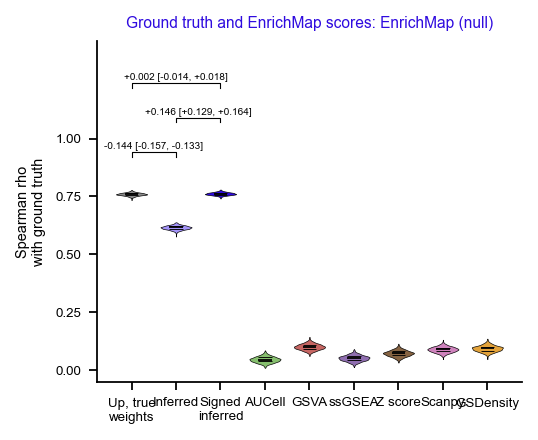

In [24]:
# Sup. Fig. 10b figure (full version): single panel
xlab = {
    "Upregulated in HRD (positive weights)": "Up, true\nweights",
    "Inferred": "Inferred",
    "Signed inferred": "Signed\ninferred"
}

condition_colours = {"Upregulated in HRD (positive weights)": "#8c8c8c", "Inferred": "#a393f8",
                     "Signed inferred": "#2f0bdf"}

fig, ax = plt.subplots(figsize=(5.6, 2.8))

names = [label for _, label in em_conditions] + list(comp.columns)

for v in enrichmap_variants[:1]:
    for k, name in enumerate(names):
        vals = panel_s10b[
            (panel_s10b["ground-truth variant"] == v)
            & (panel_s10b.condition == name)
        ].spearman_rho.values

        if len(vals) == 0:
            continue

        parts = ax.violinplot(
            vals, positions=[k], widths=0.7, showextrema=False
        )

        for pc in parts["bodies"]:
            pc.set_facecolor(condition_colours.get(name, colours.get(name)))
            pc.set_edgecolor("k")
            pc.set_linewidth(0.3)
            pc.set_alpha(1)

        q1, med, q3 = np.percentile(vals, [25, 50, 75])
        ax.hlines(
            [q1, med, q3],
            k - 0.15, k + 0.15,
            color="k", lw=[0.4, 0.8, 0.4]
        )

    tests = s10b_tests[
        (s10b_tests["ground-truth variant"] == v)
        & s10b_tests["paired bootstrap median difference"].notna()
    ]

    for _, t in tests.iloc[:3].iterrows():
        c, a = t["comparison"].split(" - ")
        ia, ic = names.index(a), names.index(c)

        level = {1: 0, 2: 2}[abs(ia - ic)] + (
            1 if min(ia, ic) == 1 else 0
        )
        top = 0.92 + 0.15 * level

        ax.plot(
            [ia, ia, ic, ic],
            [top, top + 0.02, top + 0.02, top],
            color="k", lw=0.5
        )
        ax.text(
            (ia + ic) / 2,
            top + 0.025,
            f"{t['paired bootstrap median difference']:+.3f} "
            f"[{t['paired bootstrap 2.5%']:+.3f}, "
            f"{t['paired bootstrap 97.5%']:+.3f}]",
            ha="center", va="bottom", fontsize=4.5
        )

    ax.set_title(
        f"Ground truth and EnrichMap scores: {v}",
        fontsize=7, color=colours[v]
    )

ax.set_xticks(range(len(names)))
ax.set_xticklabels([xlab.get(n, n) for n in names], fontsize=6)
ax.set_ylabel("Spearman rho\nwith ground truth", fontsize=6.5)
ax.tick_params(labelsize=6)

ax.set_ylim(
    min(-0.05, panel_s10b.spearman_rho.min() - 0.05),
    1.42
)
ax.set_yticks([
    t for t in np.arange(-0.25, 1.01, 0.25)
    if t >= ax.get_ylim()[0]
])

ax.grid(False)
sns.despine(ax=ax)

set_box_ratio(fig)

plt.savefig(
    figure_dir + "ExtendedDataFig8b_bootstrap_rho.pdf",
    bbox_inches="tight"
)
plt.show()

panel_s10b.to_csv(
    source_dir + "ExtendedDataFig8b_bootstrap_rho.csv",
    index=False
)


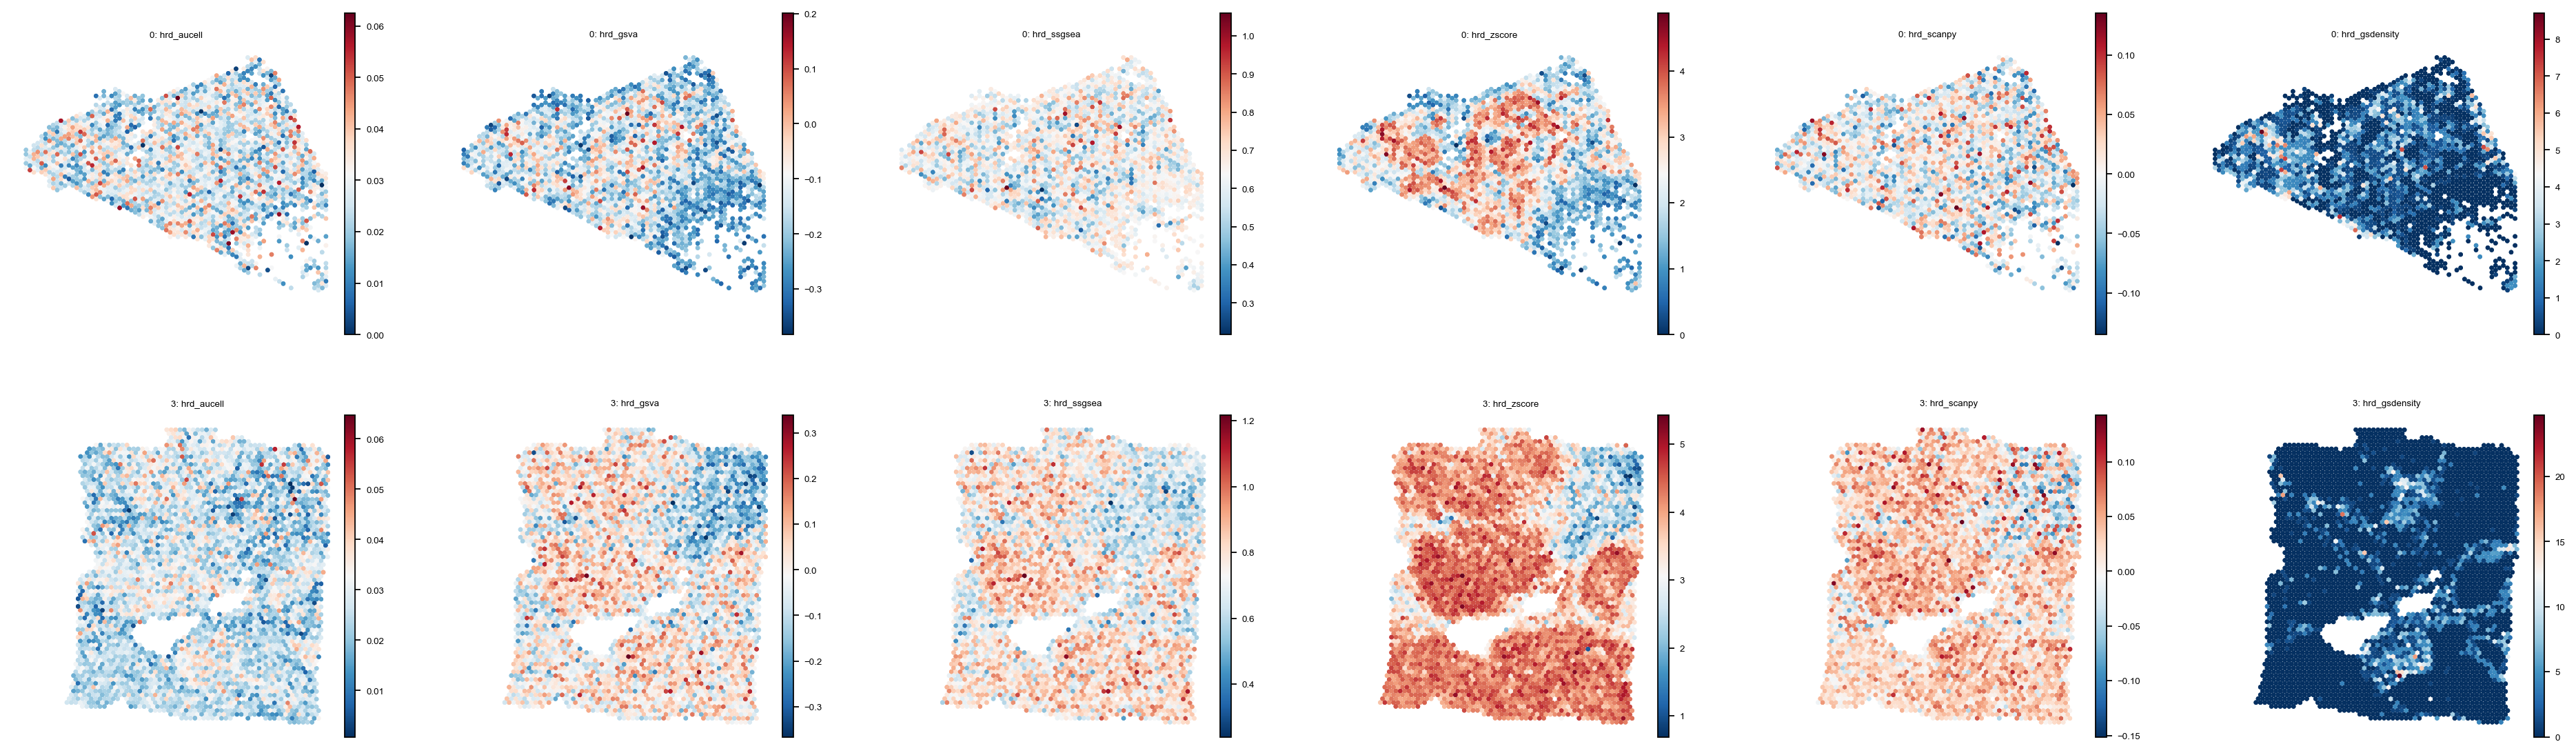

In [25]:
# 13. Sup. Fig. 10c: maps of the HRD up-gene scores of the comparators and GSDensity
keys_s10c = list(comparators.values())

em.pl.spatial_enrichmap(
    adata,
    score_key=keys_s10c,
    library_key="batch",
    ncols=len(keys_s10c),
    vcenter=None,
    save=f"ExtendedDataFig8c_comparator_maps.pdf",
    shape=None,
    size=spot_size,
)

maps_s10c = spots.copy()
for meth, key in comparators.items():
    maps_s10c[meth] = adata.obs[key].values
maps_s10c.to_csv(source_dir + "ExtendedDataFig8c_comparator_maps.csv", index=False)

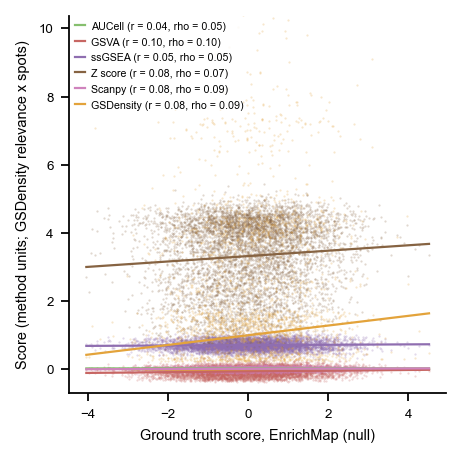

In [26]:
# 14. Sup. Fig. 10d: comparator and GSDensity scores against the ground truth (EnrichMap (null), 09_01 cell 27)
v = "EnrichMap (null)"
gt = S[v]["hrd_gt"].values
others = comp.drop(columns="GSDensity")
summary_rows = []
fig, ax = plt.subplots(figsize=(3.1, 3.1))
for meth in comp.columns:
    y = comp[meth].values
    fit = linregress(gt, y)
    r, rho = np.corrcoef(gt, y)[0, 1], spearmanr(gt, y)[0]
    summary_rows.append({"ground-truth variant": v, "method": meth, "n_spots": len(gt), "pearson_r": r,
                         "spearman_rho": rho, "ols_slope": fit.slope, "ols_intercept": fit.intercept})
    ax.scatter(gt, y, s=1, alpha=0.25, color=colours[meth], linewidths=0)
    xx = np.linspace(gt.min(), gt.max(), 10)
    ax.plot(xx, fit.intercept + fit.slope * xx, color=colours[meth], lw=1,
            label=f"{meth} (r = {r:.2f}, rho = {rho:.2f})")
# y range up to the 99th percentile of GSDensity (its long tail would squash the comparators)
y_top = max(others.values.max(), np.percentile(comp["GSDensity"], 99)) * 1.05
ax.set_ylim(min(others.values.min(), 0) - 0.3, y_top)
ax.set_xlabel(f"Ground truth score, {v}", fontsize=6.5)
ax.set_ylabel("Score (method units; GSDensity relevance x spots)", fontsize=6.5)
ax.legend(fontsize=4.8, frameon=True, facecolor="white", framealpha=0.85, edgecolor="none", loc="upper left",
          handlelength=1)
ax.tick_params(labelsize=6)
ax.grid(False)
sns.despine(ax=ax)
set_box_ratio(fig, ratio=1)
plt.savefig(figure_dir + "ExtendedDataFig8d_comparators_vs_ground_truth.pdf", bbox_inches="tight", dpi=600)
plt.show()
s10d_stats = pd.DataFrame(summary_rows)

panel_s10d = spots.assign(hrd_gt_null_score=gt)
for meth in comp.columns:
    panel_s10d[meth] = comp[meth].values
panel_s10d.to_csv(source_dir + "ExtendedDataFig8d_comparators_vs_ground_truth.csv", index=False)